# **Latin Grammar Question Intent Classifier** - Dataset Preparation

Loads the CSV of question/intent pairs, splits into train/val/test, encodes intents as numerical labels, tokenises everything with the BERT tokenizer, and visualises the intent distribution. Saves the processed datasets and intent metadata for the training and evaluation notebooks.

## **Import Dependencies**

In [31]:
import os
import sys
import json
import pandas as pd
import datasets
from datasets import Dataset
import torch
import transformers
from transformers import BertTokenizer
import sklearn
from sklearn.model_selection import train_test_split
import matplotlib
import matplotlib.pyplot as plt

In [32]:
%matplotlib inline

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
os.chdir('/content/drive/MyDrive/FYP')

In [36]:
print(torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

False
Using device: cpu


In [37]:
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python: 3.12.13
PyTorch: 2.10.0+cpu
Transformers: 5.0.0
Datasets: 4.0.0
scikit-learn: 1.6.1
pandas: 2.2.2
Matplotlib: 3.10.0
CUDA: None
GPU: none


## **Prepare Data**

### Load Dataset

In [38]:
DATA_PATH = os.path.join("data_with_oos.csv")

In [39]:
# load necessary columns into df
df = pd.read_csv(DATA_PATH, usecols=['question', 'intent'])
df.head()

,intent,question
0,part_of_speech,Is īnfrēnā a proper name or not?
1,part_of_speech,What POS is adprobātūrum?
2,part_of_speech,Is carnārium used as a verb or something else?
3,part_of_speech,Is augurātiōnibus a noun or not?
4,part_of_speech,Part of speech for synodontītidum?


In [40]:
# dataset summary
print(f"Dataset size: {len(df)} rows")
print(f"Intents: {df['intent'].value_counts().to_dict()}")

Dataset size: 1170 rows
Intents: {'part_of_speech': 100, 'person': 100, 'mood': 100, 'tense': 100, 'voice': 100, 'aspect': 100, 'number': 100, 'case': 100, 'gender': 100, 'declension': 100, 'conjugation': 100, 'oos': 70}


### Split into Train/Test/Validation Sets

In [41]:
# 70% train, 15% test, 15% val
train_df, test_val_df = train_test_split(df, test_size=0.3, random_state=42)
test_df, val_df = train_test_split(test_val_df, test_size=0.5, random_state=42)

In [42]:
print(len(train_df), "train samples")
print(len(test_df), "test samples")
print(len(val_df), "validation samples")

819 train samples
175 test samples
176 validation samples


### Data Preprocessing

In [43]:
# encode intents as numerical labels
intents = sorted(train_df['intent'].unique())
print("Total number of intents:", len(intents))

intent2label = {intent: i for i, intent in enumerate(intents)} # label mappings
label2intent = {i: intent for i, intent in enumerate(intents)}

print("Intent to Label:", intent2label)
print("Label to Intent:", label2intent)

Total number of intents: 12
Intent to Label: {'aspect': 0, 'case': 1, 'conjugation': 2, 'declension': 3, 'gender': 4, 'mood': 5, 'number': 6, 'oos': 7, 'part_of_speech': 8, 'person': 9, 'tense': 10, 'voice': 11}
Label to Intent: {0: 'aspect', 1: 'case', 2: 'conjugation', 3: 'declension', 4: 'gender', 5: 'mood', 6: 'number', 7: 'oos', 8: 'part_of_speech', 9: 'person', 10: 'tense', 11: 'voice'}


In [44]:
# map intents in df to numerical label
train_df['label'] = train_df['intent'].map(intent2label)
val_df['label']   = val_df['intent'].map(intent2label)
test_df['label']  = test_df['intent'].map(intent2label)

train_df.head()

,intent,question,label
990,declension,Is levātōrem declension 3?,3
879,gender,What grammatical gender is disjicientī?,4
316,tense,What tense is murriet?,10
594,aspect,What aspect is sēcrētum?,0
789,case,Is reaedificātī in the vocative?,1


### Tokenize Dataset

In [45]:
# load tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

In [46]:
# tokenize function
def tokenize(batch):
    return tokenizer(
        batch["question"],
        truncation=True,
        padding="max_length",
        max_length=50
    )

In [47]:
# convert dataframes to type Dataset
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)

In [48]:
# tokenize the dataset
train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

Map:   0%|          | 0/819 [00:00<?, ? examples/s]

Map:   0%|          | 0/176 [00:00<?, ? examples/s]

Map:   0%|          | 0/175 [00:00<?, ? examples/s]

In [49]:
print(train_dataset[0])

{'intent': 'declension', 'question': 'Is levātōrem declension 3?', 'label': 3, '__index_level_0__': 990, 'input_ids': [101, 2003, 23310, 8844, 6633, 11703, 7770, 10992, 1017, 1029, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


### Data Visualisation

In [50]:
# get intent counts
intent_counts = df['intent'].value_counts()

labels = intent_counts.index
values = intent_counts.values

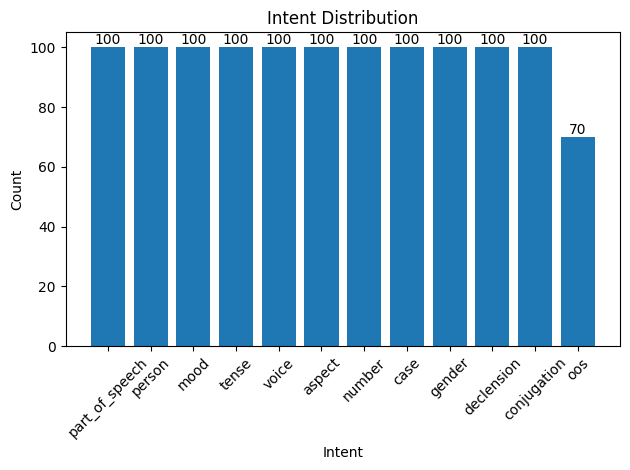

In [51]:
# Bar Chart
plt.figure()
bars = plt.bar(labels, values)

for bar in bars:
  plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), int(bar.get_height()), ha='center', va='bottom')

plt.xlabel("Intent")
plt.ylabel("Count")
plt.title("Intent Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

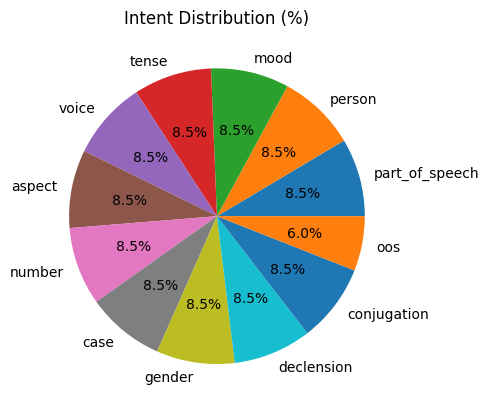

In [52]:
# Pie Chart
plt.figure()
plt.pie(values, labels=labels, autopct='%1.1f%%')
plt.title("Intent Distribution (%)")
plt.show()

## **Save Processed Data**

Save the tokenized datasets and intent metadata so the training and evaluation notebooks can load them.

In [53]:
PROCESSED_DIR = "./processed_intent"
os.makedirs(PROCESSED_DIR, exist_ok=True)

train_dataset.save_to_disk(f"{PROCESSED_DIR}/train_dataset")
val_dataset.save_to_disk(f"{PROCESSED_DIR}/val_dataset")
test_dataset.save_to_disk(f"{PROCESSED_DIR}/test_dataset")

with open(f"{PROCESSED_DIR}/intent2label.json", "w") as f:
    json.dump(intent2label, f, indent=2)

# intent_counts is a pandas Series ordered by frequency - save as a list of
# [name, count] pairs to preserve that order, then reconstruct in evaluation.
with open(f"{PROCESSED_DIR}/intent_counts.json", "w") as f:
    json.dump([[name, int(count)] for name, count in intent_counts.items()], f, indent=2)

print("Saved processed data to", PROCESSED_DIR)

Saving the dataset (0/1 shards):   0%|          | 0/819 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/176 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/175 [00:00<?, ? examples/s]

Saved processed data to ./processed_intent
